,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Public,Positive,3,No,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Public,Negative,4,No,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Public,Neutral,4,No,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Public,Negative,4,No,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Public,Neutral,4,No,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
312,28,71,Medium,Medium,No,8,69,High,Yes,1,Private,Neutral,1,No,Moderate,Female,67
313,20,80,Low,High,No,8,81,Medium,Yes,3,Private,Negative,4,No,Near,Male,69
314,24,90,Low,Low,No,7,83,Medium,Yes,0,Private,Positive,3,No,NaN,Male,68
315,18,80,Medium,Medium,No,8,55,Low,Yes,2,Public,Neutral,3,No,Moderate,Male,63



Dimension of DataFrame
(317, 17)

Column Names
Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'School_Type', 'Peer_Influence',
       'Physical_Activity', 'Learning_Disabilities', 'Distance_from_Home',
       'Gender', 'Exam_Score'],
      dtype='str')

First 5 Rows


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Public,Positive,3,No,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Public,Negative,4,No,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Public,Neutral,4,No,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Public,Negative,4,No,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Public,Neutral,4,No,Near,Female,70



Mean of Hours Studied = 20.113564668769715
Mean of Exam Score = 67.17034700315457

Slope = 0.2568601790850421
Intercept = 62.00397318029581

Linear Regression Equation:
Exam Score = 0.2568601790850421 * Hours Studied + 62.00397318029581

First 5 Predicted Scores:
Hours Studied = 23 Actual Score = 67 Predicted Score = 67.91175729925178
Hours Studied = 19 Actual Score = 61 Predicted Score = 66.88431658291161
Hours Studied = 24 Actual Score = 74 Predicted Score = 68.16861747833681
Hours Studied = 29 Actual Score = 71 Predicted Score = 69.45291837376203
Hours Studied = 19 Actual Score = 70 Predicted Score = 66.88431658291161

R-Squared = 0.15059689983571944


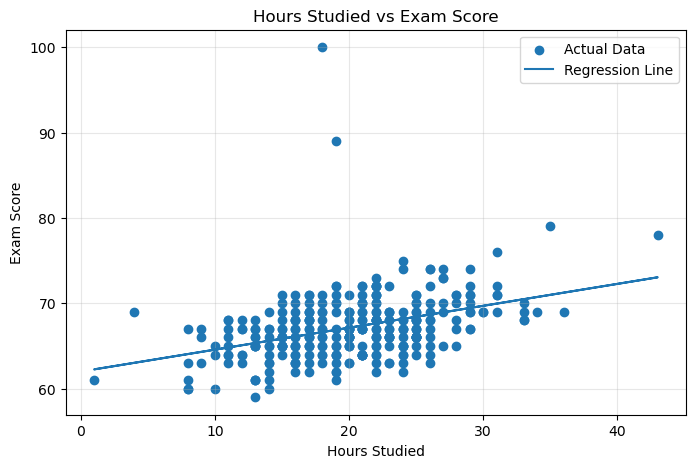


Enter Hours Studied:  9


Predicted Exam Score = 64.31571479206119


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- READ DATASET --------------------

df = pd.read_csv("dataset.csv")

display(df)

print("\nDimension of DataFrame")
print(df.shape)

print("\nColumn Names")
print(df.columns)

print("\nFirst 5 Rows")
display(df.head(5))


# =====================================================
#              SIMPLE LINEAR REGRESSION
# =====================================================

# Independent variable (X) = Hours Studied
# Dependent variable (Y) = Exam Score

data = df[["Hours_Studied", "Exam_Score"]].dropna()

x = data["Hours_Studied"]
y = data["Exam_Score"]

n = len(x)


# -------------------- MEAN OF X --------------------

sum_x = 0

for value in x:
    sum_x = sum_x + value

mean_x = sum_x / n

print("\nMean of Hours Studied =", mean_x)


# -------------------- MEAN OF Y --------------------

sum_y = 0

for value in y:
    sum_y = sum_y + value

mean_y = sum_y / n

print("Mean of Exam Score =", mean_y)


# =====================================================
# CALCULATE SLOPE
# =====================================================

# Formula:
#
#       Σ(x - mean_x)(y - mean_y)
# m = -----------------------------
#           Σ(x - mean_x)^2


numerator = 0
denominator = 0

for i in range(n):

    x_difference = x.iloc[i] - mean_x
    y_difference = y.iloc[i] - mean_y

    numerator = numerator + (x_difference * y_difference)

    denominator = denominator + (x_difference ** 2)


slope = numerator / denominator

print("\nSlope =", slope)


# =====================================================
# CALCULATE INTERCEPT
# =====================================================

# Formula:
#
# intercept = mean_y - slope * mean_x

intercept = mean_y - (slope * mean_x)

print("Intercept =", intercept)


# =====================================================
# REGRESSION EQUATION
# =====================================================

print("\nLinear Regression Equation:")

print("Exam Score =", slope, "* Hours Studied +", intercept)


# =====================================================
# PREDICT EXAM SCORES
# =====================================================

predicted_scores = []

for value in x:

    prediction = slope * value + intercept

    predicted_scores.append(prediction)


print("\nFirst 5 Predicted Scores:")

for i in range(5):

    print(
        "Hours Studied =", x.iloc[i],
        "Actual Score =", y.iloc[i],
        "Predicted Score =", predicted_scores[i]
    )


# =====================================================
#             R-SQUARED
# =====================================================

# R-squared tells how well the regression line
# explains the variation in Exam Score.

ss_total = 0
ss_residual = 0

for i in range(n):

    actual = y.iloc[i]
    predicted = predicted_scores[i]

    ss_total = ss_total + (actual - mean_y) ** 2

    ss_residual = ss_residual + (actual - predicted) ** 2


r_squared = 1 - (ss_residual / ss_total)

print("\nR-Squared =", r_squared)


# =====================================================
#                 SCATTER PLOT
# =====================================================

plt.figure(figsize=(8, 5))

# Actual data
plt.scatter(x, y, label="Actual Data")

# Regression line
plt.plot(x, predicted_scores, label="Regression Line")

plt.title("Hours Studied vs Exam Score")

plt.xlabel("Hours Studied")

plt.ylabel("Exam Score")

plt.grid(alpha=0.3)

plt.legend()

plt.show()


# =====================================================
#            USER INPUT PREDICTION
# =====================================================

hours = float(input("\nEnter Hours Studied: "))

predicted_exam_score = slope * hours + intercept

print("Predicted Exam Score =", predicted_exam_score)